<p class="lead">Notebook 2 established that a molecule's descriptors carry its provenance: the
depositing database is recoverable at ROC AUC 0.954 and the source publication at a median of
0.993. This notebook takes that fact seriously and asks what it does to the standard way of
validating a model. The answer is that random <em>k</em>-fold cross-validation, the default in
almost every tutorial, is the wrong estimator for these data — and the difference is not small.
This is the methodological heart of Farías-Abarca et al. <sup class="c"><a href="#r1">[1]</a></sup>
and the part of the paper you are most likely to reuse in your own work.</p>

<div class="box key">
<h4>Learning objectives</h4>
<ul class="objectives">
<li>Define data leakage in general terms and recognise three concrete forms of it.</li>
<li>Quantify near-duplicate leakage across a train/test boundary and explain why random splitting
measures analogue recognition.</li>
<li>Use <code>GroupKFold</code> correctly: choose a grouping variable, check how many effective
groups it gives, and say what the resulting estimate means.</li>
<li>Explain what a property-matched comparison is, implement 1:1 nearest-neighbour matching, and
compute standardized mean differences before and after it.</li>
<li>Apply the SMD &lt; 0.1 balance convention, and show why balancing four covariates does not
balance the 39 a model can see.</li>
<li>Reproduce the two endpoints of the paper's five-design comparison and read the published table
for the rest.</li>
<li>Run y-scrambling, build a null envelope, and state precisely what it does and does not
establish.</li>
<li>Apply a validation checklist to a project of your own.</li>
</ul>
</div>

<p><b>How to read this notebook.</b> Read it once in order; every number in the text comes from the
cell above it. The structure is deliberately adversarial: each section builds an estimate, then
breaks it. A <b>key idea</b> box states something to reproduce from memory, a <b>warning</b> box
names a common mistake, and a <b>bridge</b> box links to another notebook.</p>

In [1]:
# --- setup: imports, deterministic seeds, and data access ------------------
# In Google Colab the next line installs RDKit (about 30 s). Locally it is a
# no-op because RDKit is already present.
!pip -q install rdkit 2>/dev/null

import io, os, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RANDOM_STATE = 42          # the seed used throughout the published analysis
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 110, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

REPO = "https://raw.githubusercontent.com/DanielBustosG/Urease-provenance-audit/main/"
LOCAL = next((p for p in ("data", "../data", "../../data") if os.path.isdir(p)), None)

def fetch(relpath):
    """Return a file-like object for a path inside the published repository.

    Looks for a local copy first so the notebook works offline; falls back to
    the raw file on GitHub, which is what happens in Colab.
    """
    local_map = {"data/processed/": "processed/", "results/tables/": "tables/"}
    if LOCAL:
        for prefix, sub in local_map.items():
            if relpath.startswith(prefix):
                cand = os.path.join(LOCAL, sub, os.path.basename(relpath))
                if os.path.exists(cand):
                    return open(cand, "rb")
        cand = os.path.join(LOCAL, os.path.basename(relpath))
        if os.path.exists(cand):
            return open(cand, "rb")
    with urllib.request.urlopen(REPO + relpath, timeout=60) as r:
        return io.BytesIO(r.read())

def load_table(relpath, **kw):
    """Read a .parquet or .csv from the repository into a DataFrame."""
    buf = fetch(relpath)
    return (pd.read_parquet(buf, **kw) if relpath.endswith(".parquet")
            else pd.read_csv(buf, **kw))

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| data source:", "local ./%s" % LOCAL if LOCAL else "GitHub (raw)")

pandas 3.0.3 | numpy 2.4.6 | data source: local ./../data


## 1. Data leakage

### 1.1 The general definition

**The problem it solves.** We want an estimate of how a model will perform on data it has never
seen. Every validation scheme is an attempt to simulate that situation using data we already have.
Leakage is the name for every way in which the simulation fails.

<div class="box key">
<h4>Definition</h4>
<p><b>Data leakage</b> occurs when information that would not be available at prediction time is
used, directly or indirectly, to produce the estimate of performance. The estimate is then
optimistic by an unknown amount, and the model can look excellent while being useless in
deployment.</p>
</div>

The phrase "would not be available at prediction time" is the operative one. Leakage is not a
property of an algorithm or of a dataset in isolation; it is a mismatch between the validation
protocol and the real deployment situation. The same split can be perfectly sound for one intended
use and badly leaky for another, which is why you cannot decide whether a design leaks without
first stating what question the model is meant to answer. A recent survey of reproducibility
failures across machine-learning-based science found leakage to be the single most common cause,
affecting hundreds of papers in fields from medicine to political science
<sup class="c"><a href="#r2">[2]</a></sup>.

### 1.2 Three concrete forms

**Target leakage.** A feature encodes the label, usually because it was recorded after the outcome
was known. The classic example is a hospital dataset in which "number of oncology referrals"
predicts cancer diagnosis almost perfectly; the feature is a consequence of the label, not a
predictor of it <sup class="c"><a href="#r3">[3]</a></sup>. In cheminformatics the analogous error
is predicting "is a known inhibitor" from a descriptor block that includes a flag derived from the
activity record.

**Train–test contamination.** The same object, or a near copy of it, appears on both sides of the
split. The model does not generalise; it recognises. This is the dominant form in chemical datasets
and is the subject of Section 2.

**Temporal or structural leakage.** The split ignores an ordering or a grouping that will be
present at deployment. If a model will be applied to compounds from publications that do not yet
exist, then validating it on a random subset of existing publications overstates its performance,
because the test molecules come from series the model has already met. Time-split validation was
introduced in QSAR for exactly this reason <sup class="c"><a href="#r4">[4]</a></sup>.

### 1.3 The two that matter here

The urease corpus suffers from the last two, and from a specific interaction between them.

*Near-duplicate analogues across a split.* A medicinal-chemistry paper reports a congeneric
series: one scaffold, twenty substituent variations. Split those twenty molecules at random and the
test molecules differ from their training neighbours by a methyl group. Predicting them is
interpolation inside a series, not generalisation to new chemistry
<sup class="c"><a href="#r5">[5]</a></sup>.

*Publication structure across a split.* Notebook 2 showed that source publication is recoverable
from descriptors at AUC $\approx$ 0.99 and that it fixes the assay organism almost completely
($H(\text{organism} \mid \text{document})/H(\text{organism}) = 0.016$). A random split therefore
places molecules from the same publication — same laboratory, same assay protocol, same organism,
same chemical series — on both sides of the boundary. Whatever the model learns about that
publication transfers to its test molecules for free.

<div class="box warn">
<h4>Deduplication does not fix this</h4>
<p>Students often assume that removing exact duplicates (identical InChIKeys) removes
contamination. It does not. The problem is not identical molecules but <em>near</em>-identical
ones: a Tanimoto similarity of 0.95 between a test molecule and a training molecule leaks almost as
much as an exact duplicate, and no deduplication step will catch it. Section 2 measures how much of
this there is.</p>
</div>

In [2]:
ui   = load_table("data/processed/uiref_analysis.parquet")
clue = load_table("data/processed/collection_CLUE.parquet")

DESC = ["MolWt", "ExactMolWt", "NumHeavyAtoms", "NumAtoms", "LogP", "MolMR", "TPSA",
        "HBA", "HBD", "RotatableBonds", "RingCount", "AromaticRings", "AliphaticRings",
        "FractionCSP3", "BertzCT", "FormalCharge", "NumAmideBonds", "NumHeteroAtoms",
        "NumAromaticHeterocycles", "NumAliphaticHeterocycles", "NumAromaticCarbocycles",
        "NumAliphaticCarbocycles", "HeavyAtomMolWt", "NHOHCount", "NOCount"]
MATCH = ["MolWt", "LogP", "TPSA", "NumHeavyAtoms"]      # the paper's four matching covariates

# the paper removes CLUE molecules that are already in UI-Ref, so the label is well defined
dupes = set(ui["inchikey"]) & set(clue["inchikey"])
comp  = clue[~clue["inchikey"].isin(dupes)].reset_index(drop=True)
print("UI-Ref molecules      :", len(ui))
print("CLUE molecules         :", len(clue), "| already in UI-Ref:", len(dupes),
      "| used as negatives:", len(comp))
print("pooled comparison set  :", len(ui) + len(comp), "molecules,",
      "prevalence of the positive class = %.3f" % (len(ui) / (len(ui) + len(comp))))

UI-Ref molecules      : 1218
CLUE molecules         : 4431 | already in UI-Ref: 14 | used as negatives: 4417
pooled comparison set  : 5635 molecules, prevalence of the positive class = 0.216


The pooled UI-Ref-against-CLUE comparison has 5,635 molecules, which is the sample size the paper
reports for this comparison in its supplementary table S6
<sup class="c"><a href="#r1">[1]</a></sup>. Fourteen CLUE entries share an InChIKey with a UI-Ref
molecule and are removed: a molecule cannot be both the positive and the negative class.

## 2. Measuring near-duplicate leakage

**Why this analysis exists.** Before accusing a validation design of leaking, measure the leak.
The quantity to measure is, for each test molecule, the similarity to its nearest training
molecule. If that similarity is routinely high, the test set is not independent of the training set
in any meaningful sense.

**What would refute the claim.** If the nearest-training-neighbour similarity were low under random
splitting — say a median Tanimoto below 0.4, the usual threshold for "unrelated chemistry" — then
random folds would not be measuring analogue recognition, and the paper's objection to them would
collapse.

We use ECFP4 fingerprints <sup class="c"><a href="#r8">[8]</a></sup> and the Tanimoto coefficient,
which for two binary fingerprints $A$ and $B$ is

$$T(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{a}{a + b + c},$$

with $a$ the number of bits set in both, $b$ those set only in $A$ and $c$ those set only in $B$. It
runs from 0 (no shared substructure) to 1 (identical fingerprints). As a rough guide in this bit
space, $T \ge 0.9$ means near-identical molecules, $T \ge 0.7$ means close analogues from the same
series, and $T \le 0.4$ means unrelated scaffolds.

Work one similarity by hand before trusting any library to compute a million of them. Take the first
two molecules of UI-Ref. Their ECFP4 fingerprints set 25 and 39 bits respectively; 7 bits are set in
both, 18 only in the first and 32 only in the second, so the union contains $7 + 18 + 32 = 57$ bits
and

$$T = \frac{a}{a + b + c} = \frac{7}{7 + 18 + 32} = \frac{7}{57} = 0.1228 .$$

Two molecules from the same reference set that share only an eighth of their substructure
environments: UI-Ref is not uniformly congeneric, which is why the distribution in Figure 1 matters
more than any single pair.

In [3]:
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")

gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)      # ECFP4
mols = [Chem.MolFromSmiles(s) for s in ui["smiles_std"]]
assert all(m is not None for m in mols), "a UI-Ref SMILES failed to parse"
fps  = [gen.GetFingerprint(m) for m in mols]

# hand-worked Tanimoto for the first two UI-Ref molecules
A = np.asarray(gen.GetFingerprintAsNumPy(mols[0]), dtype=bool)
B = np.asarray(gen.GetFingerprintAsNumPy(mols[1]), dtype=bool)
a_, b_, c_ = int((A & B).sum()), int((A & ~B).sum()), int((B & ~A).sum())
print(ui.row_id.iloc[0], "vs", ui.row_id.iloc[1])
print("bits set in both (a) = %d | only in A (b) = %d | only in B (c) = %d" % (a_, b_, c_))
print("by hand  a/(a+b+c) = %d/%d = %.4f" % (a_, a_ + b_ + c_, a_ / (a_ + b_ + c_)))
print("RDKit    TanimotoSimilarity = %.4f" % DataStructs.TanimotoSimilarity(fps[0], fps[1]))

UIREF-0001 vs UIREF-0002
bits set in both (a) = 7 | only in A (b) = 18 | only in B (c) = 32
by hand  a/(a+b+c) = 7/57 = 0.1228
RDKit    TanimotoSimilarity = 0.1228


The experiment below computes, inside UI-Ref alone, the full $1{,}218 \times 1{,}218$ similarity
matrix and then asks the same question under three fold-assignment schemes: random stratified
folds, folds grouped by source document, and folds grouped by Bemis–Murcko scaffold
<sup class="c"><a href="#r6">[6]</a></sup>.

In [4]:
# full pairwise Tanimoto matrix; the diagonal is zeroed so a molecule is never its own neighbour
S = np.array([DataStructs.BulkTanimotoSimilarity(f, fps) for f in fps])
np.fill_diagonal(S, 0.0)
print("similarity matrix:", S.shape)
print("median Tanimoto to the nearest other UI-Ref molecule: %.3f" % np.median(S.max(axis=1)))

similarity matrix: (1218, 1218)
median Tanimoto to the nearest other UI-Ref molecule: 0.750


Before splitting anything: the median UI-Ref molecule has another UI-Ref molecule at Tanimoto
0.750. The paper reports exactly this value as the within-set nearest-neighbour median, against
0.355 for CLUE, 0.409 for DSSTox and 0.333 for COCONUT
<sup class="c"><a href="#r1">[1]</a></sup>. UI-Ref is a collection of close analogues; that is what
a target-focused library assembled from medicinal-chemistry papers looks like. The question is what
a random split does with it.

In [5]:
from sklearn.model_selection import StratifiedKFold, GroupKFold

schemes = {
    "random 5-fold":   list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
                            .split(np.zeros(len(ui)), ui["lab_published"].fillna(0))),
    "document-grouped": list(GroupKFold(n_splits=5)
                             .split(np.zeros(len(ui)), groups=ui["grp_document"].values)),
    "scaffold-grouped": list(GroupKFold(n_splits=5)
                             .split(np.zeros(len(ui)), groups=ui["scaffold"].fillna("none").values)),
}

maxsim = {}
for name, folds in schemes.items():
    m = np.zeros(len(ui))
    for tr, te in folds:                      # nearest *training* neighbour of each test molecule
        m[te] = S[np.ix_(te, tr)].max(axis=1)
    maxsim[name] = m

leak = pd.DataFrame({k: {"median max-T": np.median(v).round(3),
                         "fraction >= 0.7": round(float((v >= 0.7).mean()), 3),
                         "fraction >= 0.9": round(float((v >= 0.9).mean()), 3)}
                     for k, v in maxsim.items()}).T
print(leak.to_string())

                  median max-T  fraction >= 0.7  fraction >= 0.9
random 5-fold            0.741            0.638            0.105
document-grouped         0.463            0.173            0.058
scaffold-grouped         0.489            0.076            0.003


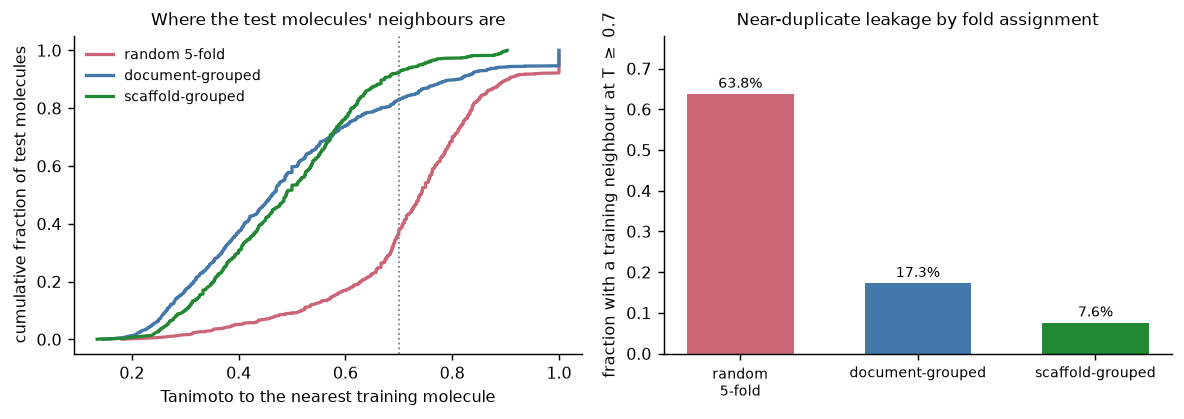

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.3))
colours = {"random 5-fold": "#cc6677", "document-grouped": "#4477aa",
           "scaffold-grouped": "#228833"}
for name, v in maxsim.items():
    xs = np.sort(v)
    axes[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), lw=1.8, color=colours[name], label=name)
axes[0].axvline(0.7, ls=":", color="grey", lw=1)
axes[0].set_xlabel("Tanimoto to the nearest training molecule")
axes[0].set_ylabel("cumulative fraction of test molecules")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left")
axes[0].set_title("Where the test molecules' neighbours are", fontsize=9.5)

names = list(maxsim)
axes[1].bar(np.arange(3), [float((maxsim[n] >= 0.7).mean()) for n in names],
            color=[colours[n] for n in names], width=0.6)
for i, n in enumerate(names):
    axes[1].text(i, float((maxsim[n] >= 0.7).mean()) + 0.015,
                 "%.1f%%" % (100 * (maxsim[n] >= 0.7).mean()), ha="center", fontsize=8)
axes[1].set_xticks(np.arange(3))
axes[1].set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=7.5)
axes[1].set_ylabel("fraction with a training neighbour at T $\\geq$ 0.7")
axes[1].set_ylim(0, 0.78)
axes[1].set_title("Near-duplicate leakage by fold assignment", fontsize=9.5)
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> Near-duplicate leakage inside UI-Ref under three fold
assignments. Left: cumulative distribution of each test molecule's Tanimoto similarity to its
nearest training molecule; the dotted line marks T = 0.7. Under random folds the curve is pushed far
to the right — the median test molecule has a training neighbour at T = 0.741 — whereas grouped
folds shift the median to 0.46 (document) and 0.49 (scaffold). Right: the fraction of test molecules
with a training neighbour at T $\geq$ 0.7, falling from 63.8% under random splitting to 17.3% and
7.6% under grouping.</p>

Under random 5-fold cross-validation, **63.8%** of UI-Ref test molecules have a training molecule at
Tanimoto $\geq$ 0.7, and 10.5% have one at $\geq$ 0.9 — effectively the same compound. Grouping the
folds by source document drops the first figure to 17.3% and grouping by scaffold to 7.6%.

The paper reports approximately 64% under random splitting, falling to approximately 18% after
document grouping and 15% after scaffold grouping
<sup class="c"><a href="#r1">[1]</a></sup>. Our random and document-grouped values reproduce the
published ones almost exactly. Our scaffold-grouped value, 7.6%, is lower than the published 15%;
the published statistic is reported for the pairwise comparison designs (supplementary sheet S9),
whereas ours is computed inside UI-Ref alone, so the two are not the same quantity. The ordering and
the magnitude of the drop are reproduced in both.

<div class="box key">
<h4>What this means for the estimate</h4>
<p>A random-split cross-validated score on this dataset is, to a large extent, a measurement of
<em>how well the model recognises close analogues of molecules it has already seen</em>. That is a
real capability, and for some purposes — ranking the next compound in a series the chemist is
already making — it is the capability you want. It is not the capability implied by a claim that a
model distinguishes urease-relevant chemistry, and the paper's own summary of this result is that
"random validation therefore measures, in part, the ability to recognize close analogues from the
same published series" <sup class="c"><a href="#r1">[1]</a></sup>.</p>
</div>

<div class="exercise">
<h4>Exercise 1</h4>
<p>Change the Tanimoto cut in the right-hand panel from 0.7 to 0.5 and re-run the cell. The gap
between random and grouped folds narrows. Explain why a lower threshold makes the designs look
more similar, and decide which threshold you would report for a project of your own.</p>
</div>

## 3. Grouped cross-validation

### 3.1 The mechanics

**The problem it solves.** We need folds in which the test molecules are independent of the
training molecules in the way that matters for the intended use. If molecules cluster into groups —
publications, series, patients, hospitals, subjects — and the model will be deployed on *new
groups*, then the folds must be built from whole groups.

`GroupKFold` takes a group label per row and assigns whole groups to folds, so no group is ever
split across the boundary. Three consequences follow, all of which you should check before trusting
the result.

First, the **effective number of groups** replaces the sample size as the relevant precision
parameter. With 1,218 molecules but only 77 named publications, the number of independent units is
77, not 1,218, and no amount of molecules will buy precision that the group count does not support.

Second, the **folds become unbalanced**. `GroupKFold` greedily assigns the largest remaining group
to the currently smallest fold, which equalises fold sizes but cannot equalise class proportions;
grouped folds therefore vary more in composition, and the across-fold standard deviation of the
score is larger than under stratified random folds. That extra dispersion is information, not noise:
it tells you how much performance depends on which publications happen to be in the training set.

Third, the **grouping key must be checked for integrity**. A composite key that splits one
publication into several groups silently re-admits leakage. The paper audits exactly this: composite
document–organism and document–organism–scaffold keys placed the same document in both training and
test data for 2.0% and 69.4% of positive test assignments respectively, and the AUCs computed under
those keys were withdrawn rather than interpreted <sup class="c"><a href="#r1">[1]</a></sup>.

The schematic below contrasts the two assignments on a toy of twelve molecules drawn from three
publications. It is a diagram, not data.

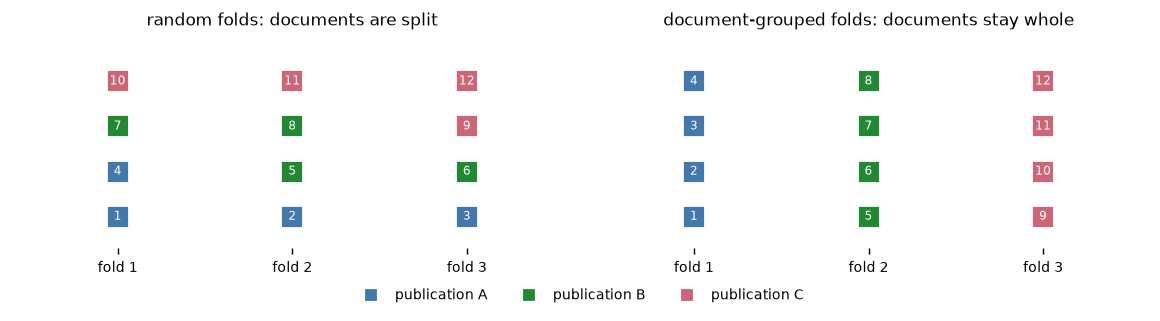

In [7]:
# conceptual diagram: random vs grouped fold assignment for 12 toy molecules in 3 documents
doc_of    = np.array([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2])
rand_fold = np.array([1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3])     # ignores the documents
grp_fold  = np.array([1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3])     # whole documents per fold
doc_col   = ["#4477aa", "#228833", "#cc6677"]

fig, axes = plt.subplots(1, 2, figsize=(9.0, 2.3), sharey=True)
for ax, folds, title in [(axes[0], rand_fold, "random folds: documents are split"),
                         (axes[1], grp_fold, "document-grouped folds: documents stay whole")]:
    for f in (1, 2, 3):
        for k, i in enumerate(np.where(folds == f)[0]):
            ax.scatter(f, k, s=160, marker="s", color=doc_col[doc_of[i]], edgecolor="white")
            ax.text(f, k, str(i + 1), ha="center", va="center", fontsize=6.5, color="white")
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["fold 1", "fold 2", "fold 3"], fontsize=8)
    ax.set_yticks([]); ax.set_xlim(0.4, 3.6); ax.set_ylim(-0.7, 4.0)
    ax.set_title(title, fontsize=9.5)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_visible(False)
handles = [plt.Line2D([], [], marker="s", ls="", color=c, label="publication %s" % n)
           for c, n in zip(doc_col, "ABC")]
fig.legend(handles=handles, frameon=False, fontsize=7.5, ncol=3,
           loc="lower center", bbox_to_anchor=(0.5, -0.07))
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Fold assignment under random and document-grouped
cross-validation, for twelve molecules from three publications (colours). A conceptual diagram, not
data. On the left every fold contains molecules from all three publications, so a model trained on
folds 2 and 3 has already seen the series that fold 1 is testing. On the right each fold is one
publication, so testing on fold 1 means testing on a publication the model has never met — which is
the quantity we want when the model will be applied to new literature.</p>

In [8]:
grp_doc = ui["grp_document"].value_counts()
print("document grouping key over UI-Ref")
print("  distinct groups          :", len(grp_doc))
print("  named publications       :", ui["primary_document"].nunique())
print("  molecules with no document:", int(ui["primary_document"].isna().sum()),
      "(each becomes a singleton group)")
print("  largest groups           :", [int(v) for v in grp_doc.head(5)])
print("  groups with one molecule :", int((grp_doc == 1).sum()))
print("\nscaffold grouping key: %d distinct Bemis-Murcko scaffolds, largest = %d molecules"
      "" % (ui["scaffold"].nunique(), ui["scaffold"].value_counts().iloc[0]))

document grouping key over UI-Ref
  distinct groups          : 153
  named publications       : 77
  molecules with no document: 76 (each becomes a singleton group)
  largest groups           : [44, 40, 40, 37, 37]
  groups with one molecule : 84

scaffold grouping key: 214 distinct Bemis-Murcko scaffolds, largest = 275 molecules


Read the output carefully, because it is the kind of thing that decides whether a grouped design is
honest. The key has 153 groups although only 77 publications are named: the 76 molecules carrying no
document identifier each form their own singleton group. That is the conservative choice — a
molecule of unknown origin should not be assumed to share a publication with any other — but it
means 84 of the 153 groups contain a single molecule — the 76 undocumented ones plus eight
publications that contributed only one compound — and the effective number of informative groups is
77.

<div class="box bridge">
<h4>Link to the bioinformatics course</h4>
<p>This is the same problem as validating a classifier on sequencing data where several samples come
from the same patient, or where libraries were prepared in batches. Grouping by patient or by batch
is the identical operation; only the vocabulary differs.</p>
</div>

### 3.2 The demonstration

**Why this analysis exists.** Measuring the leak (Section 2) shows the folds are contaminated. It
does not tell us how much of the reported performance the contamination was worth. For that we need
the same model, the same molecules and the same metric under both fold assignments — which is a
valid comparison, because here the test molecules are the same set in both cases.

**What would refute the paper's claim.** If document-grouped cross-validation gave essentially the
same AUC as random cross-validation, the leakage measured above would be real but inconsequential,
and the paper's recommendation to group would be an unnecessary conservatism.

The estimator is the paper's: a random forest with 300 trees and class-balanced weights
<sup class="c"><a href="#r17">[17]</a></sup> on the 25 physicochemical descriptors, scored by ROC AUC
and MCC <sup class="c"><a href="#r18">[18]</a></sup>.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, matthews_corrcoef

X_pair = np.vstack([ui[DESC].values, comp[DESC].values])
y_pair = np.r_[np.ones(len(ui), int), np.zeros(len(comp), int)]      # 1 = UI-Ref
# CLUE molecules get singleton groups: they carry no publication structure of this kind
g_doc  = np.r_[ui["grp_document"].values,
               np.array(["CLUE_%d" % i for i in range(len(comp))])]
g_scaf = np.r_[ui["scaffold"].fillna("none").values, comp["scaffold"].fillna("none").values]

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=RANDOM_STATE, n_jobs=-1)

def evaluate(X, yv, splits):
    """Pooled out-of-fold AUC and MCC for one design."""
    s = cross_val_predict(rf, X, yv, cv=splits, method="predict_proba", n_jobs=1)[:, 1]
    return roc_auc_score(yv, s), matthews_corrcoef(yv, (s >= 0.5).astype(int))

results = {}
results["a. conventional random CV"] = evaluate(
    X_pair, y_pair, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_pair, y_pair))
results["b. document-grouped CV"] = evaluate(
    X_pair, y_pair, GroupKFold(n_splits=5).split(X_pair, y_pair, g_doc))
results["c. scaffold-grouped CV"] = evaluate(
    X_pair, y_pair, GroupKFold(n_splits=5).split(X_pair, y_pair, g_scaf))

print(pd.DataFrame(results, index=["AUC", "MCC"]).T.round(4).to_string())

                              AUC     MCC
a. conventional random CV  0.9571  0.7514
b. document-grouped CV     0.8558  0.5260
c. scaffold-grouped CV     0.8681  0.4671


Conventional random cross-validation gives **AUC 0.9571** with MCC 0.751. Grouping the folds by
source document drops it to **0.8558** (MCC 0.526) and grouping by scaffold to **0.8681** (MCC
0.467). Nothing about the molecules, the features or the estimator changed; only the fold assignment
did. The drop of about 0.10 AUC is the part of the conventional estimate that was publication and
analogue recognition.

The published values for these three designs on UI-Ref against CLUE are 0.957, 0.847 and 0.880
<sup class="c"><a href="#r1">[1]</a></sup>. Our random and scaffold-grouped figures agree to three
decimals; our document-grouped 0.856 is 0.009 above the published 0.847, which lies inside the
published bootstrap interval of [0.834, 0.860] and reflects a different greedy assignment of the 153
groups to five folds. Grouped designs are more sensitive to fold assignment than random ones — the
third consequence listed in Section 3.1, visible as a number.

## 4. Property matching

### 4.1 What a matched comparison is

**The problem it solves.** Grouping fixes the folds but not the comparison. UI-Ref and CLUE differ
in average molecular weight by more than 50 Da, and a classifier can separate them on size alone. If
we want to ask whether the two collections differ in anything beyond bulk properties, we must first
remove the bulk-property difference by construction.

A **matched comparison** replaces the full comparison group with a subset chosen so that its
distribution of selected covariates resembles that of the treatment group. The logic is borrowed
from observational epidemiology, where one cannot randomise exposure and instead constructs a
comparison group balanced on measured confounders <sup class="c"><a href="#r13">[13]</a></sup>. In
cheminformatics the same construction appears under the name *property-matched decoys*: benchmark
negatives are chosen to match the actives on physicochemical properties precisely so that a
screening method cannot succeed by learning the property profile of the active set
<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r10">[10]</a></sup>.

### 4.2 Nearest-neighbour matching

The algorithm the paper uses is 1:1 greedy nearest-neighbour matching without replacement on four
standardized covariates: molecular weight, cLogP, TPSA and heavy-atom count
<sup class="c"><a href="#r1">[1]</a></sup>. In detail:

1. Standardise each covariate over the pooled set, $z_{ij} = (x_{ij} - \bar{x}_j)/s_j$, so that
   daltons and unitless counts contribute comparably to a distance.
2. For each UI-Ref molecule $i$, compute the Euclidean distance in this four-dimensional space to
   every available comparison molecule.
3. Take the nearest one, assign it as the match, and remove it from the pool — *without
   replacement*, so each comparison molecule is used at most once.
4. Repeat until every treated molecule has a match.

Two details decide the quality of the result. **Greedy** means the algorithm never revisits an
earlier choice, so the result depends on the order in which treated molecules are processed; we
process the most extreme molecules first, since they have the fewest acceptable partners.
**Without replacement** keeps the matched comparison group a genuine subset of distinct molecules,
at the cost of worse matches for the molecules processed last. Optimal matching, which minimises the
total distance globally, is the standard alternative <sup class="c"><a href="#r12">[12]</a></sup>;
greedy matching is used here because it is what the paper used.

Trace the algorithm by hand on three treated molecules and four controls, using a single
standardized covariate so the distances are differences on a line:

| | $z$ | nearest unused control | distance |
|---|---|---|---|
| treated T1 | $-1.8$ | C1 at $-2.0$ | 0.2 |
| treated T2 | $+1.2$ | C4 at $+1.0$ | 0.2 |
| treated T3 | $+0.3$ | C3 at $+0.6$ | 0.3 |
| | | *(C2 at $-0.4$ never used)* | |

Processing order matters: T1 is the most extreme, so it chooses first and takes C1. Had T3 been
processed first it would have taken C3 anyway, but if C3 had been the only control near both T2 and
T3, whichever went first would have taken it and the other would have been matched badly. That is
the price of greediness, and it is why the order is stated explicitly rather than left to the row
order of the file.

In [10]:
# hand-worked trace of greedy matching on one standardized covariate
toy_t = pd.DataFrame({"z": [-1.8, 1.2, 0.3]}, index=["T1", "T2", "T3"])
toy_c = pd.DataFrame({"z": [-2.0, -0.4, 0.6, 1.0]}, index=["C1", "C2", "C3", "C4"])
D = np.abs(toy_t.z.values[:, None] - toy_c.z.values[None, :])
print("distance matrix (|z_treated - z_control|):")
print(pd.DataFrame(D, index=toy_t.index, columns=toy_c.index).round(2).to_string())

used, trace = set(), []
for i in np.argsort(-np.abs(toy_t.z.values)):            # most extreme treated molecule first
    order = [j for j in np.argsort(D[i]) if toy_c.index[j] not in used]
    j = order[0]
    used.add(toy_c.index[j])
    trace.append((toy_t.index[i], toy_c.index[j], round(float(D[i, j]), 2)))
print("\ngreedy picks:", trace)
print("controls never used:", sorted(set(toy_c.index) - used))

distance matrix (|z_treated - z_control|):
     C1   C2   C3   C4
T1  0.2  1.4  2.4  2.8
T2  3.2  1.6  0.6  0.2
T3  2.3  0.7  0.3  0.7

greedy picks: [('T1', 'C1', 0.2), ('T2', 'C4', 0.2), ('T3', 'C3', 0.3)]
controls never used: ['C2']


In [11]:
from scipy.spatial.distance import cdist

def nn_match(treated, control, feats=MATCH):
    """1:1 greedy nearest-neighbour matching without replacement on standardized feats.

    Returns the positional indices of `control` chosen as matches, in the order of
    `treated`. The most extreme treated molecules are matched first.
    """
    A = treated[feats].values.astype(float)
    B = control[feats].values.astype(float)
    pooled = np.vstack([A, B])
    mu, sd = pooled.mean(axis=0), pooled.std(axis=0, ddof=1)
    As, Bs = (A - mu) / sd, (B - mu) / sd
    D = cdist(As, Bs)                                   # Euclidean distance in z-space
    used = np.zeros(len(B), dtype=bool)
    chosen = np.full(len(A), -1, dtype=int)
    for i in np.argsort(-np.linalg.norm(As, axis=1)):    # extreme molecules first
        d = np.where(used, np.inf, D[i])
        j = int(np.argmin(d))
        used[j] = True
        chosen[i] = j
    return chosen

idx = nn_match(ui, comp)
matched = comp.iloc[idx].reset_index(drop=True)
print("treated molecules matched:", len(matched),
      "| distinct controls used:", len(set(idx)),
      "| controls available:", len(comp))
print("\nmean of the four matching covariates:")
print(pd.DataFrame({"UI-Ref": ui[MATCH].mean(), "CLUE before": comp[MATCH].mean(),
                    "CLUE after matching": matched[MATCH].mean()}).round(2).to_string())

treated molecules matched: 1218 | distinct controls used: 1218 | controls available: 4417

mean of the four matching covariates:
               UI-Ref  CLUE before  CLUE after matching
MolWt          338.31       391.52               335.80
LogP             3.12         2.60                 3.05
TPSA            76.90        93.64                75.90
NumHeavyAtoms   22.84        27.25                23.43


Every UI-Ref molecule receives a distinct CLUE partner, so the matched comparison is 1,218 against
1,218 — the n = 2,436 the paper reports for its matched designs
<sup class="c"><a href="#r1">[1]</a></sup>. The means move visibly: CLUE's mean molecular weight
falls from 392 Da to 336 Da against UI-Ref's 338 Da, and heavy-atom count from 27.3 to 23.4 against
22.8. Means, however, are not a balance diagnostic, which is the subject of the next section.

### 4.3 The standardized mean difference

**The problem it solves.** "The means are now close" is not a criterion: close on what scale?
A 5 Da difference in molecular weight is negligible; a 5-unit difference in cLogP is enormous. A
balance diagnostic must be unitless.

The **standardized mean difference** divides the difference in means by a pooled standard deviation
<sup class="c"><a href="#r11">[11]</a></sup>:

$$\mathrm{SMD} = \frac{\bar{x}_{\text{treated}} - \bar{x}_{\text{control}}}
{\sqrt{\tfrac{1}{2}\left(s^{2}_{\text{treated}} + s^{2}_{\text{control}}\right)}} .$$

It expresses the group difference in units of the within-group spread, so covariates measured on
different scales become comparable, and — unlike a $t$-test or its $p$-value — it does not depend
on sample size. That last property is why balance is reported as an SMD and not as a significance
test: with 12,000 comparison molecules, a difference far too small to matter will be "significant",
and with 60 it will not, although the imbalance is the same.

Work one by hand. Three treated molecules with molecular weights 300, 320 and 340 Da have mean 320
and variance $((-20)^2 + 0 + 20^2)/2 = 400$; three controls at 360, 380 and 400 Da have mean 380 and
the same variance. The pooled denominator is $\sqrt{(400 + 400)/2} = 20$, so

$$\mathrm{SMD} = \frac{320 - 380}{20} = -3.0 ,$$

a difference of three within-group standard deviations — grossly imbalanced, and the sign tells you
the treated group is lighter.

The conventional cut-off is $|\mathrm{SMD}| < 0.1$, proposed as a rule of thumb for declaring a
covariate balanced after matching <sup class="c"><a href="#r11">[11]</a></sup>. It is a convention,
not a theorem: there is no result showing that 0.1 is where confounding becomes negligible, and the
right threshold depends on how strongly the covariate relates to the outcome. Treat it as a
reporting standard that lets readers compare across studies.

In [12]:
# hand-worked SMD, to check the function defined in the next cell
t_mw = np.array([300.0, 320.0, 340.0])
c_mw = np.array([360.0, 380.0, 400.0])
den  = np.sqrt(0.5 * (np.var(t_mw, ddof=1) + np.var(c_mw, ddof=1)))
print("treated mean %.0f (var %.0f) | control mean %.0f (var %.0f) | pooled SD %.0f"
      "" % (t_mw.mean(), np.var(t_mw, ddof=1), c_mw.mean(), np.var(c_mw, ddof=1), den))
print("SMD by hand = (320 - 380) / 20 = %.1f" % ((t_mw.mean() - c_mw.mean()) / den))

treated mean 320 (var 400) | control mean 380 (var 400) | pooled SD 20
SMD by hand = (320 - 380) / 20 = -3.0


In [13]:
def smd(a, b):
    """Standardized mean difference between two samples, pooled-SD denominator."""
    va, vb = np.var(a, ddof=1), np.var(b, ddof=1)
    den = np.sqrt(0.5 * (va + vb))
    return 0.0 if den == 0 else float((np.mean(a) - np.mean(b)) / den)

bal4 = pd.DataFrame([{"covariate": f,
                      "SMD before": round(smd(ui[f].values, comp[f].values), 3),
                      "SMD after":  round(smd(ui[f].values, matched[f].values), 3)}
                     for f in MATCH]).set_index("covariate")
print("the four matching covariates:")
print(bal4.to_string())

s7 = load_table("results/tables/tableS7_matching_smd.csv")
print("\npublished values for the same four covariates (table S7):")
print(s7[s7.comparison == "UI-Ref vs CLUE"][["feature", "smd_before", "smd_after"]]
      .round(3).to_string(index=False))

the four matching covariates:
               SMD before  SMD after
covariate                           
MolWt              -0.285      0.019
LogP                0.218      0.030
TPSA               -0.242      0.027
NumHeavyAtoms      -0.338     -0.062

published values for the same four covariates (table S7):
      feature  smd_before  smd_after
        MolWt      -0.285      0.026
         LogP       0.218      0.019
         TPSA      -0.242      0.040
NumHeavyAtoms      -0.338     -0.052


Matching works, on the covariates it was given. The absolute SMDs fall from 0.218–0.338 to
0.019–0.062, all comfortably below 0.1. Our "before" values reproduce the published ones to three
decimals (−0.285, 0.218, −0.242, −0.338) and our "after" values agree with the published
0.026, 0.019, 0.040 and −0.052 to within 0.015, the residual coming from the order in which greedy
matching processes ties. The paper reports that across all three collections the largest absolute
SMD on the matching variables fell from 0.883 to 0.053, with all twelve values below 0.1 after
matching <sup class="c"><a href="#r1">[1]</a></sup>.

If the analysis stopped here, the matched comparison would be described as balanced. Section 4.4 is
about why that description is not warranted.

### 4.4 Balance on everything the model can see

**Why this analysis exists.** A balance diagnostic restricted to the matching variables is
circular: the matching algorithm optimised those variables, so of course they balance. The question
that matters is whether the *features the classifier actually receives* are balanced — and the
classifier receives 25 descriptors, not four.

**What would refute the paper's claim.** If matching on four properties happened to balance the
remaining 21 descriptors as a side effect — because descriptors are correlated — then the matched
comparison would be adequately controlled and the paper's objection would not stand.

In [14]:
bal25 = pd.DataFrame([{"descriptor": f,
                       "SMD_before": smd(ui[f].values, comp[f].values),
                       "SMD_after":  smd(ui[f].values, matched[f].values),
                       "matched_on": f in MATCH} for f in DESC])
bal25["abs_after"] = bal25.SMD_after.abs()

n_before = int((bal25.SMD_before.abs() > 0.1).sum())
n_after   = int((bal25.abs_after > 0.1).sum())
print("of the 25 descriptors, |SMD| > 0.1 before matching: %d | after matching: %d"
      "" % (n_before, n_after))
print("\nworst-balanced descriptors after matching:")
print(bal25.sort_values("abs_after", ascending=False)
      [["descriptor", "SMD_before", "SMD_after", "matched_on"]].head(8).round(3).to_string(index=False))

of the 25 descriptors, |SMD| > 0.1 before matching: 23 | after matching: 13

worst-balanced descriptors after matching:
              descriptor  SMD_before  SMD_after  matched_on
            FractionCSP3      -1.076     -0.812       False
  NumAromaticCarbocycles       0.594      0.620       False
          AliphaticRings      -0.810     -0.565       False
 NumAliphaticCarbocycles      -0.466     -0.422       False
NumAliphaticHeterocycles      -0.648     -0.377       False
           AromaticRings       0.288      0.345       False
                     HBD      -0.017      0.327       False
               NHOHCount      -0.081      0.224       False


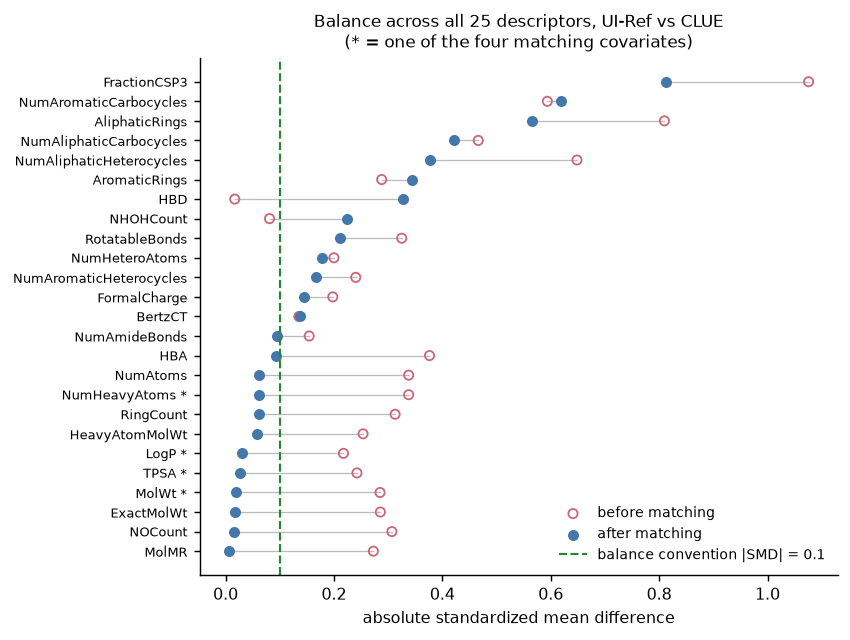

In [15]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
o = bal25.sort_values("abs_after")
ys = np.arange(len(o))
ax.scatter(o.SMD_before.abs(), ys, s=26, facecolor="none", edgecolor="#cc6677",
           label="before matching")
ax.scatter(o.abs_after, ys, s=26, color="#4477aa", label="after matching")
for yv, b, a in zip(ys, o.SMD_before.abs(), o.abs_after):
    ax.plot([b, a], [yv, yv], color="#bbbbbb", lw=0.7, zorder=0)
ax.axvline(0.1, ls="--", color="#228833", lw=1.2, label="balance convention |SMD| = 0.1")
ax.set_yticks(ys)
ax.set_yticklabels([d + (" *" if m else "") for d, m in zip(o.descriptor, o.matched_on)],
                   fontsize=7)
ax.set_xlabel("absolute standardized mean difference")
ax.set_title("Balance across all 25 descriptors, UI-Ref vs CLUE\n(* = one of the four matching covariates)",
             fontsize=9.5)
ax.legend(frameon=False, fontsize=7.5, loc="lower right")
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Absolute standardized mean difference for each of the 25
descriptors before (open red) and after (filled blue) 1:1 nearest-neighbour matching on four
properties, UI-Ref against CLUE. The dashed line is the |SMD| = 0.1 balance convention. The four
matching covariates, marked with an asterisk, move from 0.22–0.34 to below 0.07. Thirteen of the 25
descriptors remain above 0.1, headed by FractionCSP3, which matching moved only from 1.076 to
0.812.</p>

Matching on four properties balanced those four properties and left **13 of the 25 descriptors**
above the 0.1 convention. The worst offender, the fraction of sp3 carbons, sits at 0.812 after
matching. This is the descriptor that ranked first or second in the paper's SHAP analysis of the
conventional cross-collection models <sup class="c"><a href="#r1">[1]</a></sup>: the single feature
the classifier leans on hardest is among the least balanced.

The paper's own count for the 25-descriptor block is 14, 15 and 13 covariates above 0.1 for CLUE,
COCONUT and DSSTox, with maxima of 0.811 and 1.104 for FractionCSP3
<sup class="c"><a href="#r1">[1]</a></sup>. Our CLUE count of 13 against the published 14 differs by
one borderline descriptor, and our FractionCSP3 maximum of 0.812 reproduces the published 0.811.

The models in the paper's cascade see more than descriptors: they also see 14 substructure
indicators — chelating motifs such as hydroxamate and thiourea, and the PAINS, Brenk and NIH alert
flags — for a total of 39 covariates. Those indicators are assigned by SMARTS patterns frozen in the
paper's analysis package, so rather than re-deriving them we read the published balance table.

In [16]:
s35 = load_table("results/tables/tableS35_balance_sensitivity.csv")
cb  = s35[s35.block == "covariate_balance"]

cb = cb.assign(unbalanced=cb.abs_smd_after > 0.1)
summary = cb.groupby("collection").agg(covariates=("item", "size"),
                                       above_0p1_after=("unbalanced", "sum"),
                                       max_abs_smd_after=("abs_smd_after", "max")).round(3)
print(summary.to_string())
print("\nkey urease-relevant motifs, SMD before and after matching:")
print(cb[cb.item.isin(["thiourea", "any_chelator", "hydroxamate", "FractionCSP3"])]
      [["collection", "item", "item_type", "smd_before", "smd_after"]]
      .round(3).to_string(index=False))

            covariates  above_0p1_after  max_abs_smd_after
collection                                                
CLUE                39               27              0.811
COCONUT             39               25              1.104
DSSTox              39               26              0.753

key urease-relevant motifs, SMD before and after matching:
collection         item         item_type  smd_before  smd_after
      CLUE FractionCSP3        descriptor      -1.071     -0.811
      CLUE  hydroxamate substructure_flag       0.169      0.162
      CLUE     thiourea substructure_flag       0.799      0.800
      CLUE any_chelator substructure_flag       0.554      0.539
   COCONUT FractionCSP3        descriptor      -1.649     -1.104
   COCONUT  hydroxamate substructure_flag       0.164      0.174
   COCONUT     thiourea substructure_flag       0.801      0.796
   COCONUT any_chelator substructure_flag       0.573      0.500
    DSSTox FractionCSP3        descriptor      -0.845     -0

Across the 39 covariates the models can use, **27 for CLUE, 25 for COCONUT and 26 for DSSTox remain
above an absolute SMD of 0.1 after matching**, with maxima above 1.0. The published table reproduces
in our reading exactly the counts the paper states <sup class="c"><a href="#r1">[1]</a></sup>.

The identity of the unbalanced covariates is what makes this consequential rather than merely
untidy. The SMD for thiourea after matching is 0.800, 0.796 and 0.753 across the three collections —
essentially unchanged from 0.799, 0.801 and 0.773 before — and for the presence of any chelating
motif it is 0.539, 0.500 and 0.745. Thiourea and metal chelation are not incidental descriptors in
this context: they are the chemistry by which urease inhibitors are believed to act, through
coordination of the dinuclear nickel centre. The matched comparison therefore leaves the two classes
differing most in precisely the chemistry under discussion.

<div class="box key">
<h4>Matching four properties balances four properties</h4>
<p>A matching procedure is an optimiser. It balances what it is given and makes no promise about
anything else. Always report balance on the full covariate set the model can see, not on the
matching variables — the latter is a check that the optimiser ran, not that the comparison is
controlled. The paper's conclusion is blunt: "describing the matched comparison as balanced is
therefore not warranted" <sup class="c"><a href="#r1">[1]</a></sup>.</p>
</div>

<div class="box warn">
<h4>More aggressive balancing is not automatically better</h4>
<p>The obvious response is to balance all 25 descriptors instead of four. The paper tried four such
schemes — entropy balancing <sup class="c"><a href="#r19">[19]</a></sup>, coarsened exact matching,
propensity-score weighting and Mahalanobis matching on the full descriptor block. Entropy balancing
drove the maximum absolute SMD over the 25 descriptors to 0.000, but at the cost of an effective
control sample of 63 of 12,000 molecules for COCONUT, which makes that estimate imprecise. Across
the five schemes the corrected AUC ranged from 0.670 to 0.781 for CLUE, 0.690 to 0.879 for COCONUT
and 0.700 to 0.803 for DSSTox, and the direction of the change depended on the scheme
<sup class="c"><a href="#r1">[1]</a></sup>. Perfect balance on a handful of molecules is not more
informative than imperfect balance on many; this is why the paper reports a range alongside each
point estimate.</p>
</div>

## 5. The five designs side by side

**Why this analysis exists.** Sections 3 and 4 each corrected one defect. The paper's Figure 3a puts
all the corrections on one axis so that a reader can see how much each contributes and where the
estimate lands when they are combined <sup class="c"><a href="#r1">[1]</a></sup>. The five designs
are: (a) conventional random cross-validation; (b) folds grouped by source document; (c) folds
grouped by Bemis–Murcko scaffold; (d) property-matched negatives with random folds; (e) matched
negatives with document-grouped folds.

**What would refute the paper's claim.** If the fully corrected design (e) returned an AUC close to
the conventional one, the conventional comparison would be robust and the corrections cosmetic. The
claim at stake is that the conventional estimate is sensitive to library composition and provenance,
so the test is whether the estimate moves when those are controlled.

We reproduce all five on the UI-Ref–against–CLUE pair and read the other two collections from the
published table.

In [17]:
X_m = np.vstack([ui[DESC].values, matched[DESC].values])
y_m = np.r_[np.ones(len(ui), int), np.zeros(len(matched), int)]
g_m = np.r_[ui["grp_document"].values, np.array(["M_%d" % i for i in range(len(matched))])]

results["d. property-matched, random CV"] = evaluate(
    X_m, y_m, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_m, y_m))
results["e. matched + document-grouped"] = evaluate(
    X_m, y_m, GroupKFold(n_splits=5).split(X_m, y_m, g_m))

five = pd.DataFrame(results, index=["AUC", "MCC"]).T
five["n"] = [len(y_pair)] * 3 + [len(y_m)] * 2
print(five.round(4).to_string())
print("\nAUC lost between design (a) and design (e): %.3f"
      "" % (five.loc["a. conventional random CV", "AUC"]
         - five.loc["e. matched + document-grouped", "AUC"]))

                                   AUC     MCC     n
a. conventional random CV       0.9571  0.7514  5635
b. document-grouped CV          0.8558  0.5260  5635
c. scaffold-grouped CV          0.8681  0.4671  5635
d. property-matched, random CV  0.9296  0.7004  2436
e. matched + document-grouped   0.7672  0.4047  2436

AUC lost between design (a) and design (e): 0.190


In [18]:
s6 = load_table("results/tables/tableS6_pairwise_designs.csv")
pub = (s6[s6.design.isin(["a2_naive_randomCV", "b_doc_grouped", "c_scaffold_grouped",
                          "d_matched", "e_matched_doc_grouped"])]
       .pivot(index="design", columns="comparison", values="auc")
       .reindex(["a2_naive_randomCV", "b_doc_grouped", "c_scaffold_grouped",
                 "d_matched", "e_matched_doc_grouped"]))
pub.index = ["a. random CV", "b. document-grouped", "c. scaffold-grouped",
             "d. matched", "e. matched + grouped"]
pub["CLUE recomputed here"] = five["AUC"].values
print("published AUC per collection and design (table S6):")
print(pub.round(4).to_string())

published AUC per collection and design (table S6):
comparison            UI-Ref vs CLUE  UI-Ref vs COCONUT  UI-Ref vs DSSTox  CLUE recomputed here
a. random CV                  0.9572             0.9826            0.9603                0.9571
b. document-grouped           0.8474             0.9386            0.8654                0.8558
c. scaffold-grouped           0.8802             0.9538            0.8785                0.8681
d. matched                    0.9282             0.9414            0.9231                0.9296
e. matched + grouped          0.7836             0.8381            0.7597                0.7672


The recomputed CLUE column tracks the published one: 0.9571 against 0.9572 for the conventional
design and 0.7672 against 0.7836 for the fully corrected design. The paper's main text reports
0.766 for this corrected estimate with a 95% interval of [0.747, 0.785]
<sup class="c"><a href="#r1">[1]</a></sup>, which is where our 0.7672 falls; the released table's
0.7836 comes from a later re-run of the same pipeline, and the two intervals overlap. For COCONUT
and DSSTox we read the table: 0.9826 falling to 0.8381, and 0.9603 falling to 0.7597.

Across the three collections the paper summarises the whole figure as AUCs of 0.956–0.982 under the
conventional design collapsing to 0.762–0.841 after property matching and publication-grouped
validation, with MCC falling from 0.753–0.789 to 0.385–0.497
<sup class="c"><a href="#r1">[1]</a></sup>. Our CLUE endpoints — 0.957 to 0.767 in AUC and 0.751 to
0.405 in MCC — reproduce both ends of that range on the pair we recomputed.

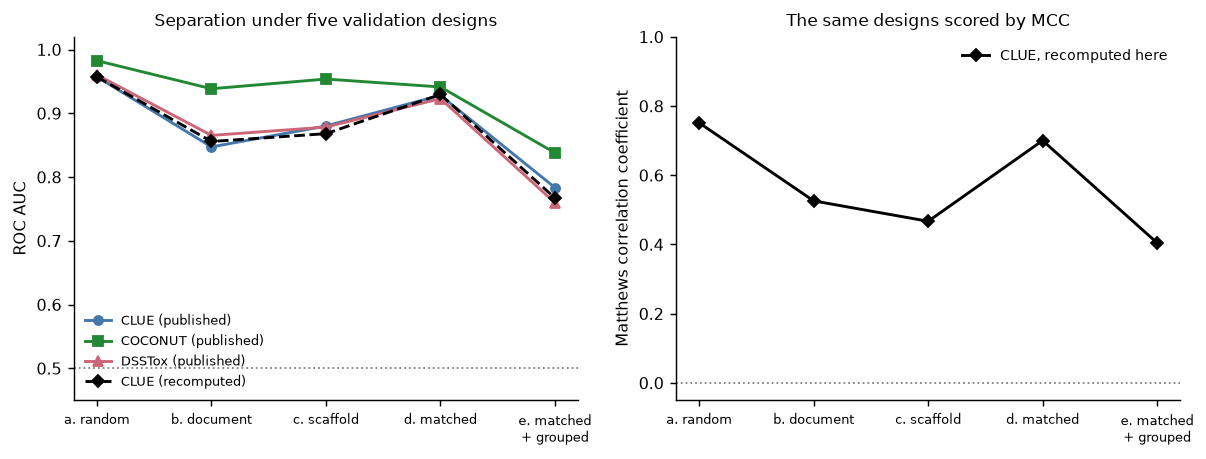

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6), sharex=True)
labels = ["a. random", "b. document", "c. scaffold", "d. matched", "e. matched\n+ grouped"]
xs = np.arange(5)

for col, colour, mark in [("UI-Ref vs CLUE", "#4477aa", "o"),
                          ("UI-Ref vs COCONUT", "#228833", "s"),
                          ("UI-Ref vs DSSTox", "#cc6677", "^")]:
    axes[0].plot(xs, pub[col].values, marker=mark, color=colour, lw=1.6, ms=5,
                 label=col.replace("UI-Ref vs ", "") + " (published)")
axes[0].plot(xs, five["AUC"].values, marker="D", color="black", lw=1.6, ms=4.5, ls="--",
             label="CLUE (recomputed)")
axes[0].axhline(0.5, ls=":", color="grey", lw=1)
axes[0].set_ylabel("ROC AUC"); axes[0].set_ylim(0.45, 1.02)
axes[0].set_xticks(xs); axes[0].set_xticklabels(labels, fontsize=7)
axes[0].set_title("Separation under five validation designs", fontsize=9.5)
axes[0].legend(frameon=False, fontsize=7, loc="lower left")

axes[1].plot(xs, five["MCC"].values, marker="D", color="black", lw=1.6, ms=4.5,
             label="CLUE, recomputed here")
axes[1].axhline(0.0, ls=":", color="grey", lw=1)
axes[1].set_ylabel("Matthews correlation coefficient"); axes[1].set_ylim(-0.05, 1.0)
axes[1].set_xticks(xs); axes[1].set_xticklabels(labels, fontsize=7)
axes[1].set_title("The same designs scored by MCC", fontsize=9.5)
axes[1].legend(frameon=False, fontsize=7.5, loc="upper right")
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> ROC AUC (left) and MCC (right) across the five validation
designs. Published values for the three collections from supplementary table S6
<sup class="c"><a href="#r1">[1]</a></sup>; the black dashed line is our recomputation for CLUE,
which falls on the published curve at every design. Each correction removes separation on its own —
grouping costs about 0.10 AUC, matching about 0.03 — and their combination costs 0.19, from 0.957 to
0.767. MCC falls in parallel, from 0.751 to 0.405, so the collapse is not an artefact of the
ranking metric.</p>

Note the non-additivity. Grouping alone costs 0.101 AUC and matching alone costs 0.028, but applying
both costs 0.190 — more than the sum. The reason is that the two defects reinforce one another: the
unmatched comparison can be won on bulk properties, which are shared across publications, so
removing the bulk-property route forces the model back onto series-specific structure, which is
exactly what grouping then removes. Corrections to a validation design are not independent
contributions you can add up, and reporting them one at a time understates the joint effect.

### 5.1 A model with no descriptors at all

**Why this analysis exists.** The corrected design still separates the collections at AUC 0.767.
Before reading that as residual chemistry, ask how much of it a model could obtain *without using
any physicochemical descriptor* — using only how similar a molecule is to the two training sets.
Such a model cannot know anything about urease; it can only recognise neighbourhoods.

The score is deliberately primitive: for each test molecule, the Tanimoto similarity to its nearest
UI-Ref training molecule minus the similarity to its nearest matched-control training molecule. One
number per molecule, no fitting, no features.

In [20]:
mols_m = [Chem.MolFromSmiles(s) for s in matched["smiles_std"]]
assert all(m is not None for m in mols_m), "a matched-control SMILES failed to parse"
fps_m  = fps + [gen.GetFingerprint(m) for m in mols_m]
S_m = np.array([DataStructs.BulkTanimotoSimilarity(f, fps_m) for f in fps_m], dtype=np.float32)
np.fill_diagonal(S_m, 0.0)

nn_auc = {}
for name, folds in [("random", list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
                                    .split(S_m, y_m))),
                    ("document-grouped", list(GroupKFold(n_splits=5).split(S_m, y_m, g_m)))]:
    score = np.zeros(len(y_m))
    for tr, te in folds:
        pos, neg = tr[y_m[tr] == 1], tr[y_m[tr] == 0]
        score[te] = S_m[np.ix_(te, pos)].max(axis=1) - S_m[np.ix_(te, neg)].max(axis=1)
    nn_auc[name] = roc_auc_score(y_m, score)

print("nearest-neighbour similarity score, no descriptors used:")
for k, v in nn_auc.items():
    print("  %-18s AUC = %.4f" % (k, v))
print("\n25-descriptor random forest, same molecules and folds:")
print("  random             AUC = %.4f" % five.loc["d. property-matched, random CV", "AUC"])
print("  document-grouped   AUC = %.4f" % five.loc["e. matched + document-grouped", "AUC"])

nearest-neighbour similarity score, no descriptors used:
  random             AUC = 0.9859
  document-grouped   AUC = 0.9024

25-descriptor random forest, same molecules and folds:
  random             AUC = 0.9296
  document-grouped   AUC = 0.7672


The descriptor-free score reaches **AUC 0.986** under random folds and **0.902** under
document-grouped folds, against 0.930 and 0.767 for the 25-descriptor random forest on the same
molecules and the same folds. A model that knows nothing except "which training set is this molecule
closer to" outperforms the full descriptor model in the fully corrected design.

Two readings follow, and they point in different directions. The first confirms Section 2: under
random folds, nearest-neighbour recognition alone is almost sufficient, so a large part of the
conventional estimate is analogue recognition by construction. The second is more uncomfortable.
Grouping removes most of the *within-publication* analogue effect, yet the similarity score still
reaches 0.902 — because UI-Ref molecules are mutually similar (median nearest-neighbour Tanimoto
0.750) while the comparison molecules are not (0.355 for CLUE)
<sup class="c"><a href="#r1">[1]</a></sup>. "Distance to the nearest member of my own library" is
therefore not a chemical property of a molecule at all; it is a property of how the library was
assembled, and it separates the classes better than chemistry does.

<div class="box bridge">
<h4>Forward link</h4>
<p>That observation is the seed of Notebook 4. The paper formalises it as a <em>library-assembly
null</em>: replace every descriptor by five features describing a molecule's position inside its own
library — its scaffold's frequency there and its fingerprint-neighbourhood density there — and the
null reaches AUC 0.995 under the corrected design, exceeding the observed model by 0.154 to 0.234
<sup class="c"><a href="#r1">[1]</a></sup>. Our crude two-number version already shows the direction
of that result.</p>
</div>

## 6. y-scrambling

**The problem it solves.** Every analysis so far has asked how *much* separation there is. None has
asked whether the pipeline would report separation when there is none. A complicated pipeline —
matching, grouping, resampling, a flexible estimator — has many opportunities to manufacture an
apparent signal, and no amount of internal consistency will reveal that.

**y-scrambling** (also called y-randomisation or label permutation) answers that question directly
<sup class="c"><a href="#r14">[14]</a></sup>. Permute the labels at random, destroying any
relationship with the features, then run the *entire* pipeline unchanged and record the score.
Repeat many times. The resulting distribution is the **null envelope**: the performance the pipeline
reports when the labels carry no information. A correct pipeline produces a null centred on the
no-skill value — AUC 0.5 — with the spread determined by sample size and fold structure. The
observed score is then compared with that envelope, and the permutation $p$-value is

$$p = \frac{1 + \#\{\text{permutations with score} \ge \text{observed}\}}{1 + R},$$

the "+1" ensuring that $p$ is never zero, since the observed labelling is itself one of the possible
permutations. With $R$ replicates the smallest attainable value is $1/(R+1)$.

The paper runs 100 permutations for each of 17 designs <sup class="c"><a href="#r1">[1]</a></sup>.
We run 40 on the fully corrected CLUE design with 150 trees and 3 folds, to stay inside the
notebook's runtime budget; the envelope is slightly wider than the paper's as a result, which makes
our test marginally more conservative.

In [21]:
rf_perm = RandomForestClassifier(n_estimators=150, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=-1)
rng = np.random.RandomState(RANDOM_STATE)
R = 40                                 # the paper uses 100 replicates per design

null = []
for _ in range(R):
    y_perm = rng.permutation(y_m)      # destroy the label-feature relationship
    s = cross_val_predict(rf_perm, X_m, y_perm,
                          cv=GroupKFold(n_splits=3).split(X_m, y_perm, g_m),
                          method="predict_proba", n_jobs=1)[:, 1]
    null.append(roc_auc_score(y_perm, s))
null = np.array(null)

observed = five.loc["e. matched + document-grouped", "AUC"]
p_perm = (1 + int((null >= observed).sum())) / (1 + R)
print("null over %d permutations: mean %.4f | SD %.4f | 95th pct %.4f | max %.4f"
      "" % (R, null.mean(), null.std(ddof=1), np.percentile(null, 95), null.max()))
print("observed AUC (design e)  : %.4f" % observed)
print("permutation p-value      : %.4f  (smallest attainable with %d replicates: %.4f)"
      "" % (p_perm, R, 1 / (R + 1)))

null over 40 permutations: mean 0.4971 | SD 0.0168 | 95th pct 0.5231 | max 0.5324
observed AUC (design e)  : 0.7672
permutation p-value      : 0.0244  (smallest attainable with 40 replicates: 0.0244)


In [22]:
s8 = load_table("results/tables/tableS8_yscrambling.csv")
print("published null for the same design (table S8, UI-Ref vs CLUE, matched + doc-grouped):")
print(s8[(s8.comparison == "UI-Ref vs CLUE") & (s8.design == "e_matched_doc_grouped")]
      [["real_auc_5fold", "null_mean", "null_sd", "null_p95", "perm_p"]]
      .round(4).to_string(index=False))

published null for the same design (table S8, UI-Ref vs CLUE, matched + doc-grouped):
 real_auc_5fold  null_mean  null_sd  null_p95  perm_p
         0.7836     0.5005   0.0139    0.5237  0.0099


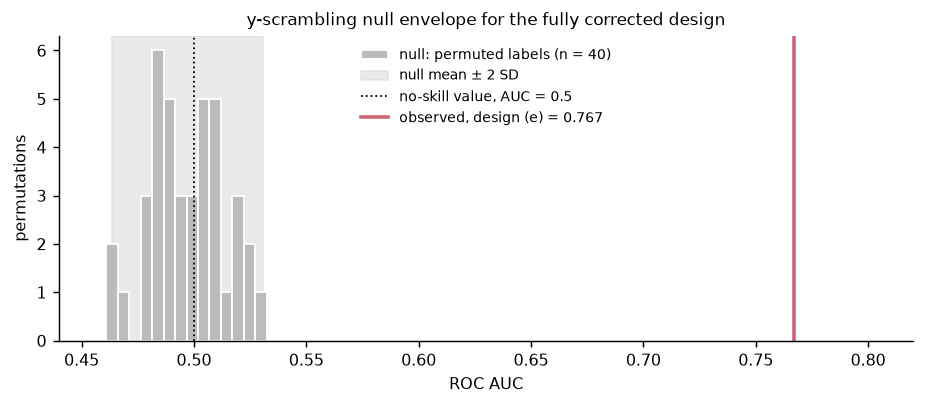

In [23]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.hist(null, bins=14, color="#bbbbbb", edgecolor="white", label="null: permuted labels (n = %d)" % R)
ax.axvspan(null.mean() - 2 * null.std(ddof=1), null.mean() + 2 * null.std(ddof=1),
           color="#dddddd", alpha=0.6, zorder=0, label="null mean $\\pm$ 2 SD")
ax.axvline(0.5, ls=":", color="black", lw=1, label="no-skill value, AUC = 0.5")
ax.axvline(observed, color="#cc6677", lw=2, label="observed, design (e) = %.3f" % observed)
ax.set_xlim(0.44, 0.82)
ax.set_xlabel("ROC AUC"); ax.set_ylabel("permutations")
ax.set_title("y-scrambling null envelope for the fully corrected design", fontsize=9.5)
ax.legend(frameon=False, fontsize=7.5, loc="upper center")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> The y-scrambling null for the fully corrected UI-Ref-against-CLUE
design: 40 label permutations run through the complete matched, document-grouped pipeline. The null
is centred at 0.497 with a standard deviation of 0.017 and a maximum of 0.532, so the pipeline
reports chance performance when the labels are uninformative. The observed AUC of 0.767 lies
sixteen null standard deviations above the mean.</p>

The null has mean **0.4971** and standard deviation 0.0168, with a 95th percentile of 0.523 and a
maximum of 0.532. The observed 0.7672 exceeds every permutation, giving $p = 0.0244$, the smallest
value attainable with 40 replicates. The published null for the same design has mean 0.5005,
standard deviation 0.0139 and a 95th percentile of 0.5237, with a permutation $p$-value of 0.0099
from 100 replicates <sup class="c"><a href="#r1">[1]</a></sup>. Our envelope is marginally wider, as
expected from fewer replicates and fewer folds; the conclusion is identical. Across all 100
permutations of all 17 designs the paper reports null means of 0.497–0.504 and every observed AUC
exceeding its null's 95th percentile <sup class="c"><a href="#r1">[1]</a></sup>.

<div class="box key">
<h4>What y-scrambling does and does not establish</h4>
<p><b>Does:</b> it shows the pipeline is not self-fulfilling — the matching, the grouping, the
resampling and the estimator together do not manufacture apparent separation from uninformative
labels. It also calibrates the no-skill value for <em>this</em> design, which is not always exactly
0.5 for small or strongly grouped samples.</p>
<p><b>Does not:</b> it says nothing about <em>what</em> the real labels encode. A permutation null
breaks the relationship between features and labels, so it cannot distinguish target chemistry from
provenance structure — both are destroyed equally. Exceeding a y-scrambling null establishes only
that some reproducible feature–label relationship exists, which is a much weaker claim than the one
usually read from it.</p>
</div>

This limitation is precisely why the paper does not stop here. Having shown that the residual
separation beats a label-permutation null, it asks what *else* could produce the same separation,
and builds nulls that keep the labels intact while replacing the features with provenance-derived
quantities. Those nulls reach AUC 0.995 on the same task — higher than the observed model
<sup class="c"><a href="#r1">[1]</a></sup>.

<div class="box bridge">
<h4>Forward link</h4>
<p>Notebook 4 constructs those task-matched nulls and explains why a label-permutation null is the
weakest member of the family.</p>
</div>

<div class="exercise">
<h4>Exercise 2</h4>
<p>Change <code>R = 40</code> to <code>R = 10</code> and re-run. The null mean barely moves but the
smallest attainable $p$-value becomes 1/11 = 0.091. Explain why the number of permutations bounds
the $p$-value from below, and how many replicates you would need to report $p < 0.01$.</p>
</div>

## 7. A checklist for your own project

The following is the procedure this notebook has been assembling, written so that you can apply it
to a dataset that has nothing to do with urease. It restates, in operational form, what the QSAR
validation literature has recommended for two decades
<sup class="c"><a href="#r16">[16]</a></sup><sup class="c"><a href="#r20">[20]</a></sup>.

**1. State the deployment question before choosing a split.** Write one sentence: "the model will be
applied to ___ that the training set does not contain." New analogues of known series, new
publications, new laboratories, new patients, new time periods — the blank determines everything
else. A design is not leaky in the abstract; it is leaky relative to that sentence.

**2. Find the grouping variables.** List every variable along which rows cluster: source publication,
assay batch, laboratory, scaffold, patient, site. For each, compute how much of the outcome's
variation it explains — the normalised conditional entropy of Notebook 2 is one convenient measure —
and check whether it will be constant or new at deployment.

**3. Group on the coarsest variable that matches the deployment question.** If the model will meet
new publications, group by publication; grouping by scaffold as well is not stricter, merely
different. Report the **effective number of groups**, not only the number of rows, and audit the key:
confirm that no group appears on both sides of any fold. A composite key almost always fails this
test.

**4. Quantify the leak you are removing.** Report the fraction of test rows with a near-duplicate
training neighbour under each design — for molecules, the nearest-neighbour Tanimoto at a stated
threshold <sup class="c"><a href="#r7">[7]</a></sup>. A design change that does not move this number
has not removed leakage.

**5. If you are comparing two groups, match them — and then check the balance on everything.** Report
SMDs before and after for *all* covariates the model can see, not only the matching variables, with
the |SMD| < 0.1 convention marked. Report the effective sample size the matching cost you. If
several balancing schemes are defensible, report the range of estimates they give rather than the
one you prefer.

**6. Run y-scrambling on the final pipeline.** Permute the labels, run everything unchanged, and
report the null mean, its standard deviation, its 95th percentile and the permutation $p$-value with
the number of replicates. State the smallest attainable $p$-value for that number.

**7. Report every design, not only the best one.** The sequence of estimates *is* the result. A
single number with no design history cannot be audited, and a reader cannot tell whether 0.95 means
0.95 or means 0.77 before the shortcuts were removed <sup class="c"><a href="#r15">[15]</a></sup>.

**8. Say what the residual separation could still be.** Beating a permutation null establishes that
a feature–label relationship exists. It does not identify what the relationship is. Name the
alternative explanations your design cannot exclude.

<div class="box warn">
<h4>The honest-sounding mistake</h4>
<p>"We used cross-validation" is not a validation statement. "We used 5-fold cross-validation
grouped by source publication, 77 effective groups, with 17% of test molecules having a training
neighbour at Tanimoto $\geq$ 0.7 against 64% under random folds" is. Always report the grouping
variable, the number of effective groups and the residual leakage; the words "cross-validation"
alone distinguish nothing.</p>
</div>

## 8. Summary

You should be able to explain the following without notes.

- **Leakage** is any use of information unavailable at prediction time in producing the performance
  estimate. It is a mismatch between the validation protocol and the deployment situation, not a
  property of the data alone. Three forms: target leakage, train–test contamination, and temporal
  or structural leakage.
- **Near-duplicate contamination is measurable.** Under random 5-fold folds, 63.8% of UI-Ref test
  molecules have a training neighbour at Tanimoto $\geq$ 0.7, falling to 17.3% under document
  grouping. A random-split score on this data measures analogue recognition to a large extent.
- **Grouped cross-validation** assigns whole groups to folds. The effective number of groups — 77
  publications, not 1,218 molecules — replaces sample size as the precision parameter; grouped folds
  are more dispersed; and the grouping key must be audited for integrity.
- **Matching** constructs a comparison group balanced on selected covariates. Greedy 1:1
  nearest-neighbour matching without replacement on four standardized properties is what this paper
  used; it costs comparison molecules and depends on processing order.
- **The SMD** is the mean difference in pooled-SD units, unitless and independent of sample size,
  which is why balance is reported as an SMD rather than a $p$-value. The |SMD| < 0.1 cut-off is a
  reporting convention, not a theorem.
- **Matching four properties balances four properties.** Thirteen of the 25 descriptors remained
  above 0.1 after matching in our recomputation (the paper reports 14 for this collection), and 27
  of the 39 covariates the models can see, including thiourea at 0.800 and chelating motifs at
  0.539 — the chemistry of interest.
- **The five designs.** AUC 0.957 under conventional random cross-validation, 0.856 document-grouped,
  0.868 scaffold-grouped, 0.930 matched, 0.767 matched and grouped, with MCC falling from 0.751 to
  0.405. The corrections are not additive: together they cost more than the sum of their individual
  effects.
- **y-scrambling** shows a pipeline does not manufacture signal from uninformative labels; our null
  was centred at 0.497 with SD 0.017 against an observed 0.767. It cannot distinguish target
  chemistry from provenance structure, because permutation destroys both.

## 9. Self-assessment

<details><summary>Q1. Give the one-sentence definition of data leakage, and explain why the same
split can be leaky for one project and sound for another.</summary>
Leakage is the use of information unavailable at prediction time in producing the performance
estimate. Whether a split leaks depends on what the model will be applied to: a random split is
sound if the model will only ever rank new analogues of known series, and leaky if it will be
applied to compounds from publications it has never seen.</details>

<details><summary>Q2. Why does removing exact duplicates not address contamination in a chemical
dataset?</summary>
Because the contamination comes from near-duplicates. A test molecule differing from a training
molecule by one methyl group has a Tanimoto similarity around 0.9 and leaks almost as much as an
exact copy, but has a different InChIKey and survives deduplication.</details>

<details><summary>Q3. UI-Ref has 1,218 molecules and 77 named publications. Which number limits the
precision of a document-grouped estimate, and why?</summary>
Seventy-seven. Under grouping, whole publications are the independent units; molecules within a
publication are not independent replicates, so adding more molecules from the same papers does not
increase the effective sample size.</details>

<details><summary>Q4. Our document-grouped AUC was 0.856 while the paper reports 0.847. Is this a
disagreement?</summary>
No. The published bootstrap interval is [0.834, 0.860], which contains 0.856. Grouped designs are
more sensitive than random ones to how the greedy group-to-fold assignment happens to fall, and the
difference is within that sensitivity.</details>

<details><summary>Q5. Why is balance reported as a standardized mean difference rather than as the
$p$-value of a $t$-test?</summary>
Because the SMD does not depend on sample size. With 12,000 control molecules a negligible
difference is "significant" and with 60 a large one is not, although the imbalance is identical. The
SMD expresses the difference in units of within-group spread, so it is comparable across covariates
and across studies.</details>

<details><summary>Q6. A reviewer says "your matched comparison is balanced, you report all SMDs
below 0.1". What do you check?</summary>
Which covariates the SMDs were computed for. If they are the matching variables only, the statement
is circular — the optimiser balanced what it was given. Ask for the balance table over every
covariate the model receives, and for the effective sample size the matching cost.</details>

<details><summary>Q7. Grouping cost 0.101 AUC, matching cost 0.028, and together they cost 0.190.
Explain the non-additivity.</summary>
The two shortcuts substitute for one another. Without matching, the model can separate the
collections on bulk properties shared across publications; removing that route forces it onto
series-specific structure, which grouping then removes. Each correction becomes more costly once the
other is in place.</details>

<details><summary>Q8. Your y-scrambling null is centred at 0.62 rather than 0.5. What does that tell
you?</summary>
That the pipeline is broken: with uninformative labels it should report no skill. A null displaced
upward usually indicates leakage inside the resampling itself — for example a preprocessing step fitted
on all the data before splitting, or a grouping key that lets the same group appear in training and
test.</details>

<details><summary>Q9. With 40 permutations, the smallest $p$-value you can report is 1/41 = 0.024.
How many replicates do you need for $p &lt; 0.001$?</summary>
At least 1,000, since the minimum attainable value is $1/(R+1)$. Permutation $p$-values are bounded
below by the resolution of the permutation set, so reporting "p &lt; 0.001" from 100 permutations is
not supportable.</details>

<details><summary>Q10. Read the code: <code>GroupKFold(n_splits=5).split(X_m, y_m, g_m)</code> where
<code>g_m</code> gives each matched control its own group. Does this grouping do anything to the
control molecules?</summary>
Effectively no: singleton groups can be assigned to any fold, so the controls are split as if at
random. The grouping constrains only the UI-Ref side, which is the side with publication structure.
This is the correct treatment, because the external library has no equivalent grouping to
respect.</details>

<details><summary>Q11. Name one thing exceeding a y-scrambling null does <em>not</em>
establish.</summary>
That the separation reflects the chemistry of the target. Permuting labels destroys every
feature–label relationship equally, so the test cannot distinguish target chemistry from residual
provenance structure. Deciding between those requires nulls that keep the labels and change the
features.</details>

## Glossary

<dl class="gloss">
<dt>Data leakage</dt><dd>Use of information unavailable at prediction time in producing a
performance estimate, making the estimate optimistic by an unknown amount.</dd>
<dt>Train–test contamination</dt><dd>The form of leakage in which the same object, or a near copy,
appears on both sides of the split.</dd>
<dt>Near-duplicate</dt><dd>A molecule whose fingerprint similarity to another is high enough that
predicting one from the other is interpolation; here, Tanimoto $\geq$ 0.7 on ECFP4.</dd>
<dt>Tanimoto coefficient</dt><dd>$|A \cap B| / |A \cup B|$ for two binary fingerprints; 0 for no
shared substructure, 1 for identical fingerprints.</dd>
<dt>GroupKFold</dt><dd>Cross-validation that assigns whole groups to folds so that no group is split
across a train/test boundary.</dd>
<dt>Effective number of groups</dt><dd>The count of independent units under a grouped design; the
quantity that limits precision, in place of the row count.</dd>
<dt>Matched comparison</dt><dd>A comparison in which the control group is replaced by a subset chosen
to resemble the treated group on selected covariates.</dd>
<dt>Greedy nearest-neighbour matching</dt><dd>Matching that pairs each treated unit with its closest
unused control in turn, without revisiting earlier choices.</dd>
<dt>Standardized mean difference</dt><dd>The difference in covariate means divided by a pooled
standard deviation; a unitless, sample-size-independent balance diagnostic.</dd>
<dt>Effective sample size</dt><dd>The number of control units a weighting or matching scheme
effectively retains; small values indicate an imprecise estimate however good the balance.</dd>
<dt>y-scrambling</dt><dd>Repeating the entire analysis with permuted labels to obtain the
distribution of scores the pipeline reports when the labels carry no information.</dd>
<dt>Null envelope</dt><dd>That distribution, summarised by its mean, dispersion and upper
percentile.</dd>
<dt>Permutation p-value</dt><dd>$(1 + \#\{\text{permutations} \ge \text{observed}\}) / (1 + R)$;
bounded below by $1/(R+1)$.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Farías-Abarca J, Urra G, Henríquez C, Yáñez O, Osorio MI, Palma J,
Morales-Quintana L, Suardíaz R, Bustos D. Provenance-Associated Confounding in Cross-Collection
Comparisons of Urease Inhibitors: A Quantified Reference Scale and a Domain-Aware Alternative.
<em>Int. J. Mol. Sci.</em> 2026;27(20):9159.
<a href="https://doi.org/10.3390/ijms27209159">doi:10.3390/ijms27209159</a></li>
<li id="r2">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based
science. <em>Patterns</em> 2023;4(9):100804.
<a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r3">Kaufman S, Rosset S, Perlich C, Stitelman O. Leakage in data mining: formulation,
detection, and avoidance. <em>ACM Trans. Knowl. Discov. Data</em> 2012;6(4):15.
<a href="https://doi.org/10.1145/2382577.2382579">doi:10.1145/2382577.2382579</a></li>
<li id="r4">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of
prospective prediction. <em>J. Chem. Inf. Model.</em> 2013;53(4):783–790.
<a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r5">Martin EJ, Polyakov VR, Tian L, Perez RC. Does rational selection of training and test
sets improve the outcome of QSAR modeling? <em>J. Chem. Inf. Model.</em> 2012;52(10):2570–2578.
<a href="https://doi.org/10.1021/ci300338w">doi:10.1021/ci300338w</a></li>
<li id="r6">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks.
<em>J. Med. Chem.</em> 1996;39(15):2887–2893.
<a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r7">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine
learning with activity cliffs. <em>J. Chem. Inf. Model.</em> 2022;62(23):5938–5951.
<a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
<li id="r8">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J. Chem. Inf. Model.</em>
2010;50(5):742–754.
<a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r9">Mysinger MM, Carchia M, Irwin JJ, Shoichet BK. Directory of useful decoys, enhanced
(DUD-E): better ligands and decoys for better benchmarking. <em>J. Med. Chem.</em>
2012;55(14):6582–6594.
<a href="https://doi.org/10.1021/jm300687e">doi:10.1021/jm300687e</a></li>
<li id="r10">Réau M, Langenfeld F, Zagury JF, Lagarde N, Montes M. Decoys selection in benchmarking
datasets: overview and perspectives. <em>Front. Pharmacol.</em> 2018;9:11.
<a href="https://doi.org/10.3389/fphar.2018.00011">doi:10.3389/fphar.2018.00011</a></li>
<li id="r11">Austin PC. Balance diagnostics for comparing the distribution of baseline covariates
between treatment groups in propensity-score matched samples. <em>Stat. Med.</em>
2009;28(25):3083–3107.
<a href="https://doi.org/10.1002/sim.3697">doi:10.1002/sim.3697</a></li>
<li id="r12">Stuart EA. Matching methods for causal inference: a review and a look forward.
<em>Stat. Sci.</em> 2010;25(1):1–21.
<a href="https://doi.org/10.1214/09-STS313">doi:10.1214/09-STS313</a></li>
<li id="r13">Rosenbaum PR, Rubin DB. The central role of the propensity score in observational
studies for causal effects. <em>Biometrika</em> 1983;70(1):41–55.
<a href="https://doi.org/10.1093/biomet/70.1.41">doi:10.1093/biomet/70.1.41</a></li>
<li id="r14">Rücker C, Rücker G, Meringer M. y-Randomization and its variants in QSPR/QSAR.
<em>J. Chem. Inf. Model.</em> 2007;47(6):2345–2357.
<a href="https://doi.org/10.1021/ci700157b">doi:10.1021/ci700157b</a></li>
<li id="r15">Golbraikh A, Tropsha A. Beware of q2! <em>J. Mol. Graph. Model.</em>
2002;20(4):269–276.
<a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r16">Tropsha A. Best practices for QSAR model development, validation, and exploitation.
<em>Mol. Inform.</em> 2010;29(6–7):476–488.
<a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r17">Breiman L. Random forests. <em>Mach. Learn.</em> 2001;45(1):5–32.
<a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r18">Matthews BW. Comparison of the predicted and observed secondary structure of T4 phage
lysozyme. <em>Biochim. Biophys. Acta</em> 1975;405(2):442–451.
<a href="https://doi.org/10.1016/0005-2795(75)90109-9">doi:10.1016/0005-2795(75)90109-9</a></li>
<li id="r19">Hainmueller J. Entropy balancing for causal effects: a multivariate reweighting method
to produce balanced samples in observational studies. <em>Polit. Anal.</em> 2012;20(1):25–46.
<a href="https://doi.org/10.1093/pan/mpr025">doi:10.1093/pan/mpr025</a></li>
<li id="r20">Muratov EN, Bajorath J, Sheridan RP, et al. QSAR without borders.
<em>Chem. Soc. Rev.</em> 2020;49(11):3525–3564.
<a href="https://doi.org/10.1039/D0CS00098A">doi:10.1039/D0CS00098A</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical
Learning with Applications in Python.</em> Springer, 2023. Chapter 5 on resampling methods. Free
PDF from the authors.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning.</em> 2nd ed.,
Springer, 2009. Section 7.10 on the right and wrong ways to cross-validate. Free PDF.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow.</em> 3rd ed.,
O'Reilly, 2022. Chapter 2 for split design in practice.</li>
<li>Imbens GW, Rubin DB. <em>Causal Inference for Statistics, Social, and Biomedical Sciences.</em>
Cambridge University Press, 2015. Part III for matching and balance.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide, "Cross-validation iterators for grouped data":
<a href="https://scikit-learn.org/stable/modules/cross_validation.html">scikit-learn.org</a></li>
<li>RDKit documentation, fingerprints and similarity:
<a href="https://www.rdkit.org/docs/">rdkit.org/docs</a></li>
<li>Analysis code and published tables for this paper:
<a href="https://github.com/DanielBustosG/Urease-provenance-audit">github.com/DanielBustosG/Urease-provenance-audit</a></li>
</ul>